# Credit default prediction

Explore applicant characteristics and their relationship with the binary `Default` target (0 = no default, 1 = default).


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src.credit.data_ingestion import DataIngestion
from IPython.display import Markdown, display

df = DataIngestion().load_all()

display(df.head(10))


,Default,checkingstatus1,duration,history,purpose,amount,savings,employ,installment,status,...,residence,property,age,otherplans,housing,cards,job,liable,tele,foreign
0,0,A11,6,A34,A43,1169,A65,A75,4,A93,...,4,A121,67,A143,A152,2,A173,1,A192,A201
1,1,A12,48,A32,A43,5951,A61,A73,2,A92,...,2,A121,22,A143,A152,1,A173,1,A191,A201
2,0,A14,12,A34,A46,2096,A61,A74,2,A93,...,3,A121,49,A143,A152,1,A172,2,A191,A201
3,0,A11,42,A32,A42,7882,A61,A74,2,A93,...,4,A122,45,A143,A153,1,A173,2,A191,A201
4,1,A11,24,A33,A40,4870,A61,A73,3,A93,...,4,A124,53,A143,A153,2,A173,2,A191,A201
5,0,A14,36,A32,A46,9055,A65,A73,2,A93,...,4,A124,35,A143,A153,1,A172,2,A192,A201
6,0,A14,24,A32,A42,2835,A63,A75,3,A93,...,4,A122,53,A143,A152,1,A173,1,A191,A201
7,0,A12,36,A32,A41,6948,A61,A73,2,A93,...,2,A123,35,A143,A151,1,A174,1,A192,A201
8,0,A14,12,A32,A43,3059,A64,A74,2,A91,...,4,A121,61,A143,A152,1,A172,1,A191,A201
9,1,A12,30,A34,A40,5234,A61,A71,4,A94,...,2,A123,28,A143,A152,2,A174,1,A191,A201


## EDA

Check the data, class balance, and relationships with default.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid", context="notebook")
colors = {"No default": "#278DAD", "Default": "#E76F51"}
data = df.assign(Outcome=df["Default"].map({0: "No default", 1: "Default"}))

print(f"{len(df):,} applicants | {df.shape[1] - 1} predictors")
print("Duplicate rows:", df.duplicated().sum())
display(df.isna().sum().to_frame("Missing values").T)
display(df.describe().T.round(2))


1,000 applicants | 20 predictors
Duplicate rows: 0


,Default,checkingstatus1,duration,history,purpose,amount,savings,employ,installment,status,...,residence,property,age,otherplans,housing,cards,job,liable,tele,foreign
Missing values,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
Default,1000.0,0.30,0.46,0.0,0.0,0.0,1.00,1.0
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
installment,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
residence,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
cards,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
liable,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0


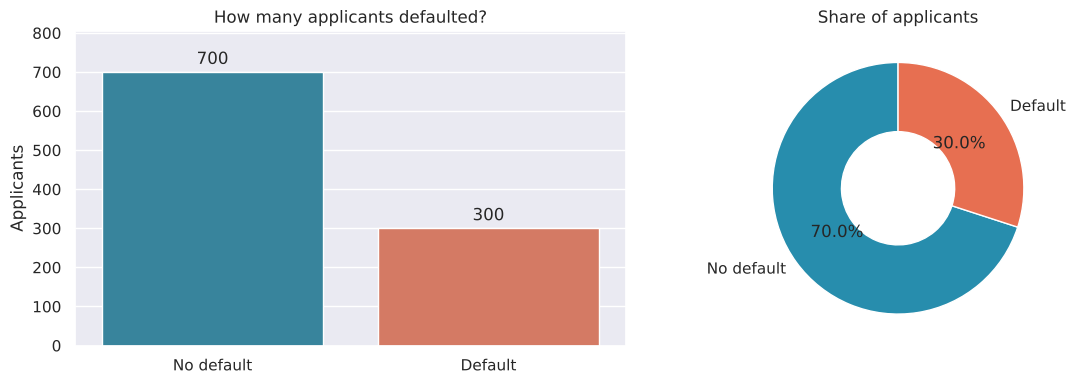

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=data, x="Outcome", hue="Outcome", palette=colors,
              order=list(colors), legend=False, ax=axes[0])
axes[0].set(title="How many applicants defaulted?", xlabel="", ylabel="Applicants")
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].bar_label(axes[0].containers[1], padding=3)
axes[0].margins(y=0.15)

counts = data["Outcome"].value_counts().reindex(list(colors), fill_value=0)
axes[1].pie(counts, labels=counts.index, colors=list(colors.values()),
            autopct="%.1f%%", startangle=90, wedgeprops={"width": 0.55})
axes[1].set_title("Share of applicants")
plt.tight_layout()
plt.show()


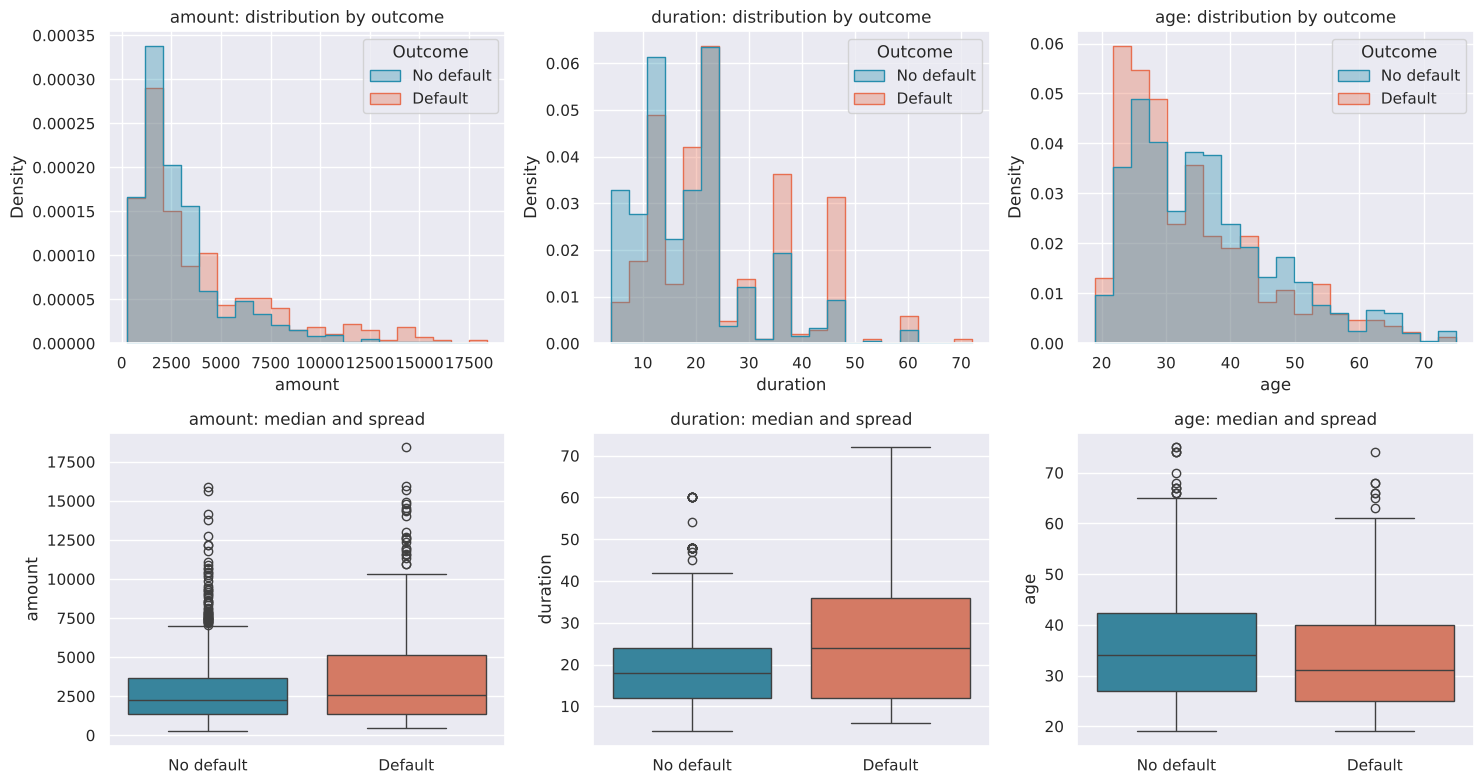

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, column in enumerate(["amount", "duration", "age"]):
    sns.histplot(data=data, x=column, hue="Outcome", palette=colors,
                 bins=20, stat="density", common_norm=False,
                 element="step", alpha=0.35, ax=axes[0, i])
    axes[0, i].set_title(f"{column}: distribution by outcome")

    sns.boxplot(data=data, x="Outcome", y=column, hue="Outcome",
                palette=colors, order=list(colors), legend=False, ax=axes[1, i])
    axes[1, i].set(xlabel="", title=f"{column}: median and spread")

plt.tight_layout()
plt.show()


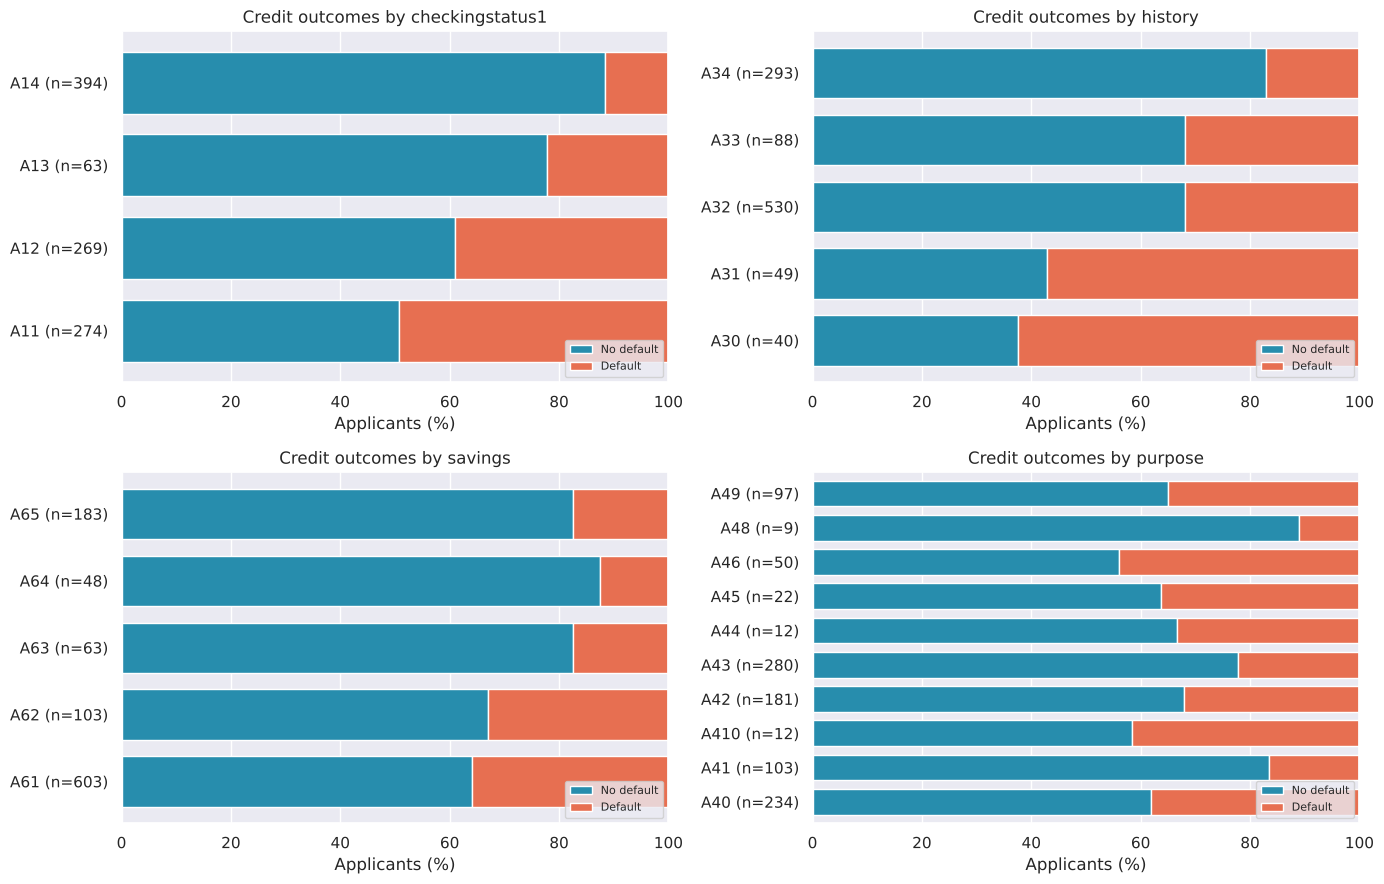

Category codes are shown as recorded. Compare percentages alongside group sizes (n).


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for column, ax in zip(["checkingstatus1", "history", "savings", "purpose"], axes.flat):
    counts = pd.crosstab(data[column], data["Outcome"]).reindex(columns=list(colors), fill_value=0)
    shares = counts.div(counts.sum(axis=1), axis=0) * 100
    shares.plot.barh(stacked=True, color=list(colors.values()), ax=ax, width=0.75)
    ax.set_yticklabels([f"{category} (n={total})" for category, total in counts.sum(axis=1).items()])
    ax.set(title=f"Credit outcomes by {column}", xlabel="Applicants (%)", ylabel="", xlim=(0, 100))
    ax.legend(title="", loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()
print("Category codes are shown as recorded. Compare percentages alongside group sizes (n).")


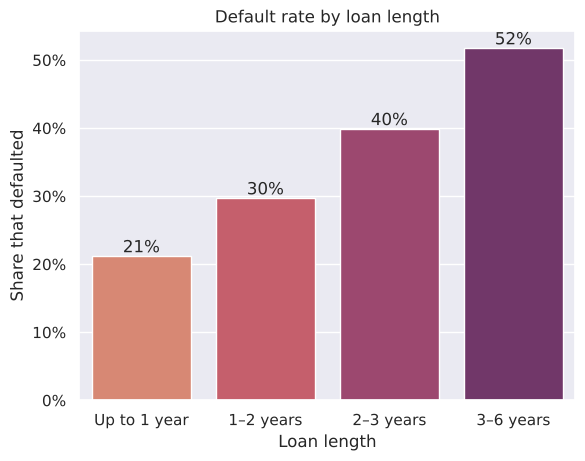

In [6]:
loan_length = pd.cut(data["duration"], bins=[0, 12, 24, 36, 72],
                     labels=["Up to 1 year", "1–2 years", "2–3 years", "3–6 years"])

ax = sns.barplot(x=loan_length, y=data["Default"], hue=loan_length, palette="flare", dodge=False, errorbar=None, legend=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:.0%}")
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set(title="Default rate by loan length", xlabel="Loan length", ylabel="Share that defaulted")
plt.show()

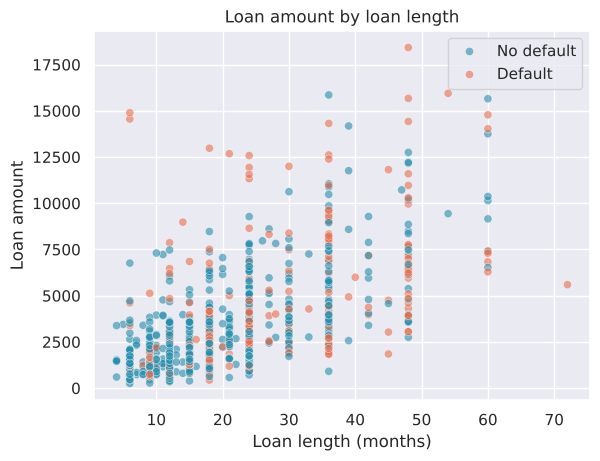

In [7]:
ax = sns.scatterplot(data=data, x="duration", y="amount", hue="Outcome", palette=colors,
                     hue_order=list(colors), alpha=0.6, s=35)
ax.legend(title="")
ax.set(title="Loan amount by loan length", xlabel="Loan length (months)", ylabel="Loan amount")
plt.show()